# 1. Ingeniería de datos y EDA desde los originales

Esta fase reconstruye realmente los datos, audita las fuentes y ejecuta el EDA. No carga salidas antiguas como si fueran una ejecución nueva. Se necesitan los ZIP declarados en README; conserve los originales. La semilla de análisis es42.

In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Abra el notebook dentro del proyecto'
os.environ['MPLCONFIGDIR']=str(ROOT/'tmp/matplotlib')
os.environ['XDG_CACHE_HOME']=str(ROOT/'tmp/cache')
sys.path.insert(0,str(ROOT/'src'))
def run_script(name,*args):
    started=time.perf_counter()
    result=subprocess.run([sys.executable,str(ROOT/'src'/name),*map(str,args)],cwd=ROOT,text=True,capture_output=True)
    (ROOT/'reports').mkdir(exist_ok=True)
    (ROOT/'reports'/f'notebook_{name}_{Path(str(args[-1])).name if args else "run"}.log').write_text(result.stdout+result.stderr)
    print(result.stdout[-4500:])
    if result.returncode: print(result.stderr); result.check_returncode()
    print(f'Ejecución real completada en {time.perf_counter()-started:.1f} segundos')
def show(name): display(Image(filename=str(ROOT/'reports/figures'/name)))
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name).head(20))
def results(): return json.loads((ROOT/'reports/results.json').read_text())
print('Python:',sys.version.split()[0], '| ejecutable del kernel:',sys.executable)


Python: 3.12.14 | ejecutable del kernel: ${PROJECT_ROOT}/.venv/bin/python


## Fuentes y reconstrucción
La carpeta se configura con IA_SOURCE_DIR; IA_ANNUAL_DIR indica la carpeta de las cuatro descargas anuales. Las rutas predeterminadas usan Downloads del usuario actual. El builder comprueba su contenido y registra hashes.

In [2]:
source=Path(os.environ.get('IA_SOURCE_DIR',Path.home()/'Downloads/DocenteMaterial'))
annual=Path(os.environ.get('IA_ANNUAL_DIR',Path.home()/'Downloads'))
run_script('build_data.py','--source-dir',source,'--annual-dir',annual)
run_script('run_analysis.py','--phase','prepare')

Loaded annual vivienda: 44,599 rows
Loaded annual personas: 115,145 rows
Loaded annual educacion: 104,446 rows
Loaded annual sumaria: 33,702 rows
Loaded vivienda: 44,599 rows in 2025
Loaded personas: 115,145 rows in 2025
Loaded educacion: 106,958 rows in 2025
Loaded sumaria: 33,702 rows in 2025
{"output": "${PROJECT_ROOT}/data/processed/dataset_enaho_escale_2025.csv", "rows": 23345, "columns": 112, "escale_match_rate": 0.9817948168772757, "digital_exclusion": {"0": 13233, "missing": 5538, "1": 4574}}

Ejecución real completada en 26.7 segundos


Cohorte y particiones 13105 3439
Completado prepare 

Ejecución real completada en 3.6 segundos


## Calidad y población
La información escolar es contexto territorial por distrito/área; no asignamos una escuela concreta a cada encuestado. Los saltos del cuestionario permanecen diferenciados de respuestas negativas.

,left_rows,right_rows,output_rows,matched,unmatched,keys,cardinality,row_multiplication
educacion,23345,104446,23345,23345,0,"[conglome, vivienda, hogar, codperso]",many_to_one,False
vivienda,23345,44599,23345,23345,0,"[conglome, vivienda, hogar]",many_to_one,False
sumaria,23345,33702,23345,23345,0,"[conglome, vivienda, hogar]",many_to_one,False
escale,23345,2439,23345,22920,425,"[ubigeo, escale_area]",many_to_one,False


Población: {'persons_2025': 115145, 'age_6_17_before_residency': 24195, 'residency_rule': '(P204=1 and P205=2) or (P204=2 and P206=1)', 'usual_residents_6_17': 23345, 'age_6_17_excluded_non_usual': 850, 'residency_codes_age_6_17': [{'p204': 1, 'p205': 2, 'p206': -999, 'n': 23242}, {'p204': 2, 'p205': -999, 'p206': 2, 'n': 550}, {'p204': 1, 'p205': 1, 'p206': -999, 'n': 300}, {'p204': 2, 'p205': -999, 'p206': 1, 'n': 103}]}
Cobertura: 0.9817948168772757


,objetivo,n_validos,n_positivos,n_negativos,prevalencia_muestral,prevalencia_ponderada,conglomerados
0,target_rezago,16544,6707,9837,0.405404,0.403578,4040
1,target_rezago_2,16544,679,15865,0.041042,0.038355,4040
2,target_internet,16544,4294,12250,0.259550,0.226711,4040


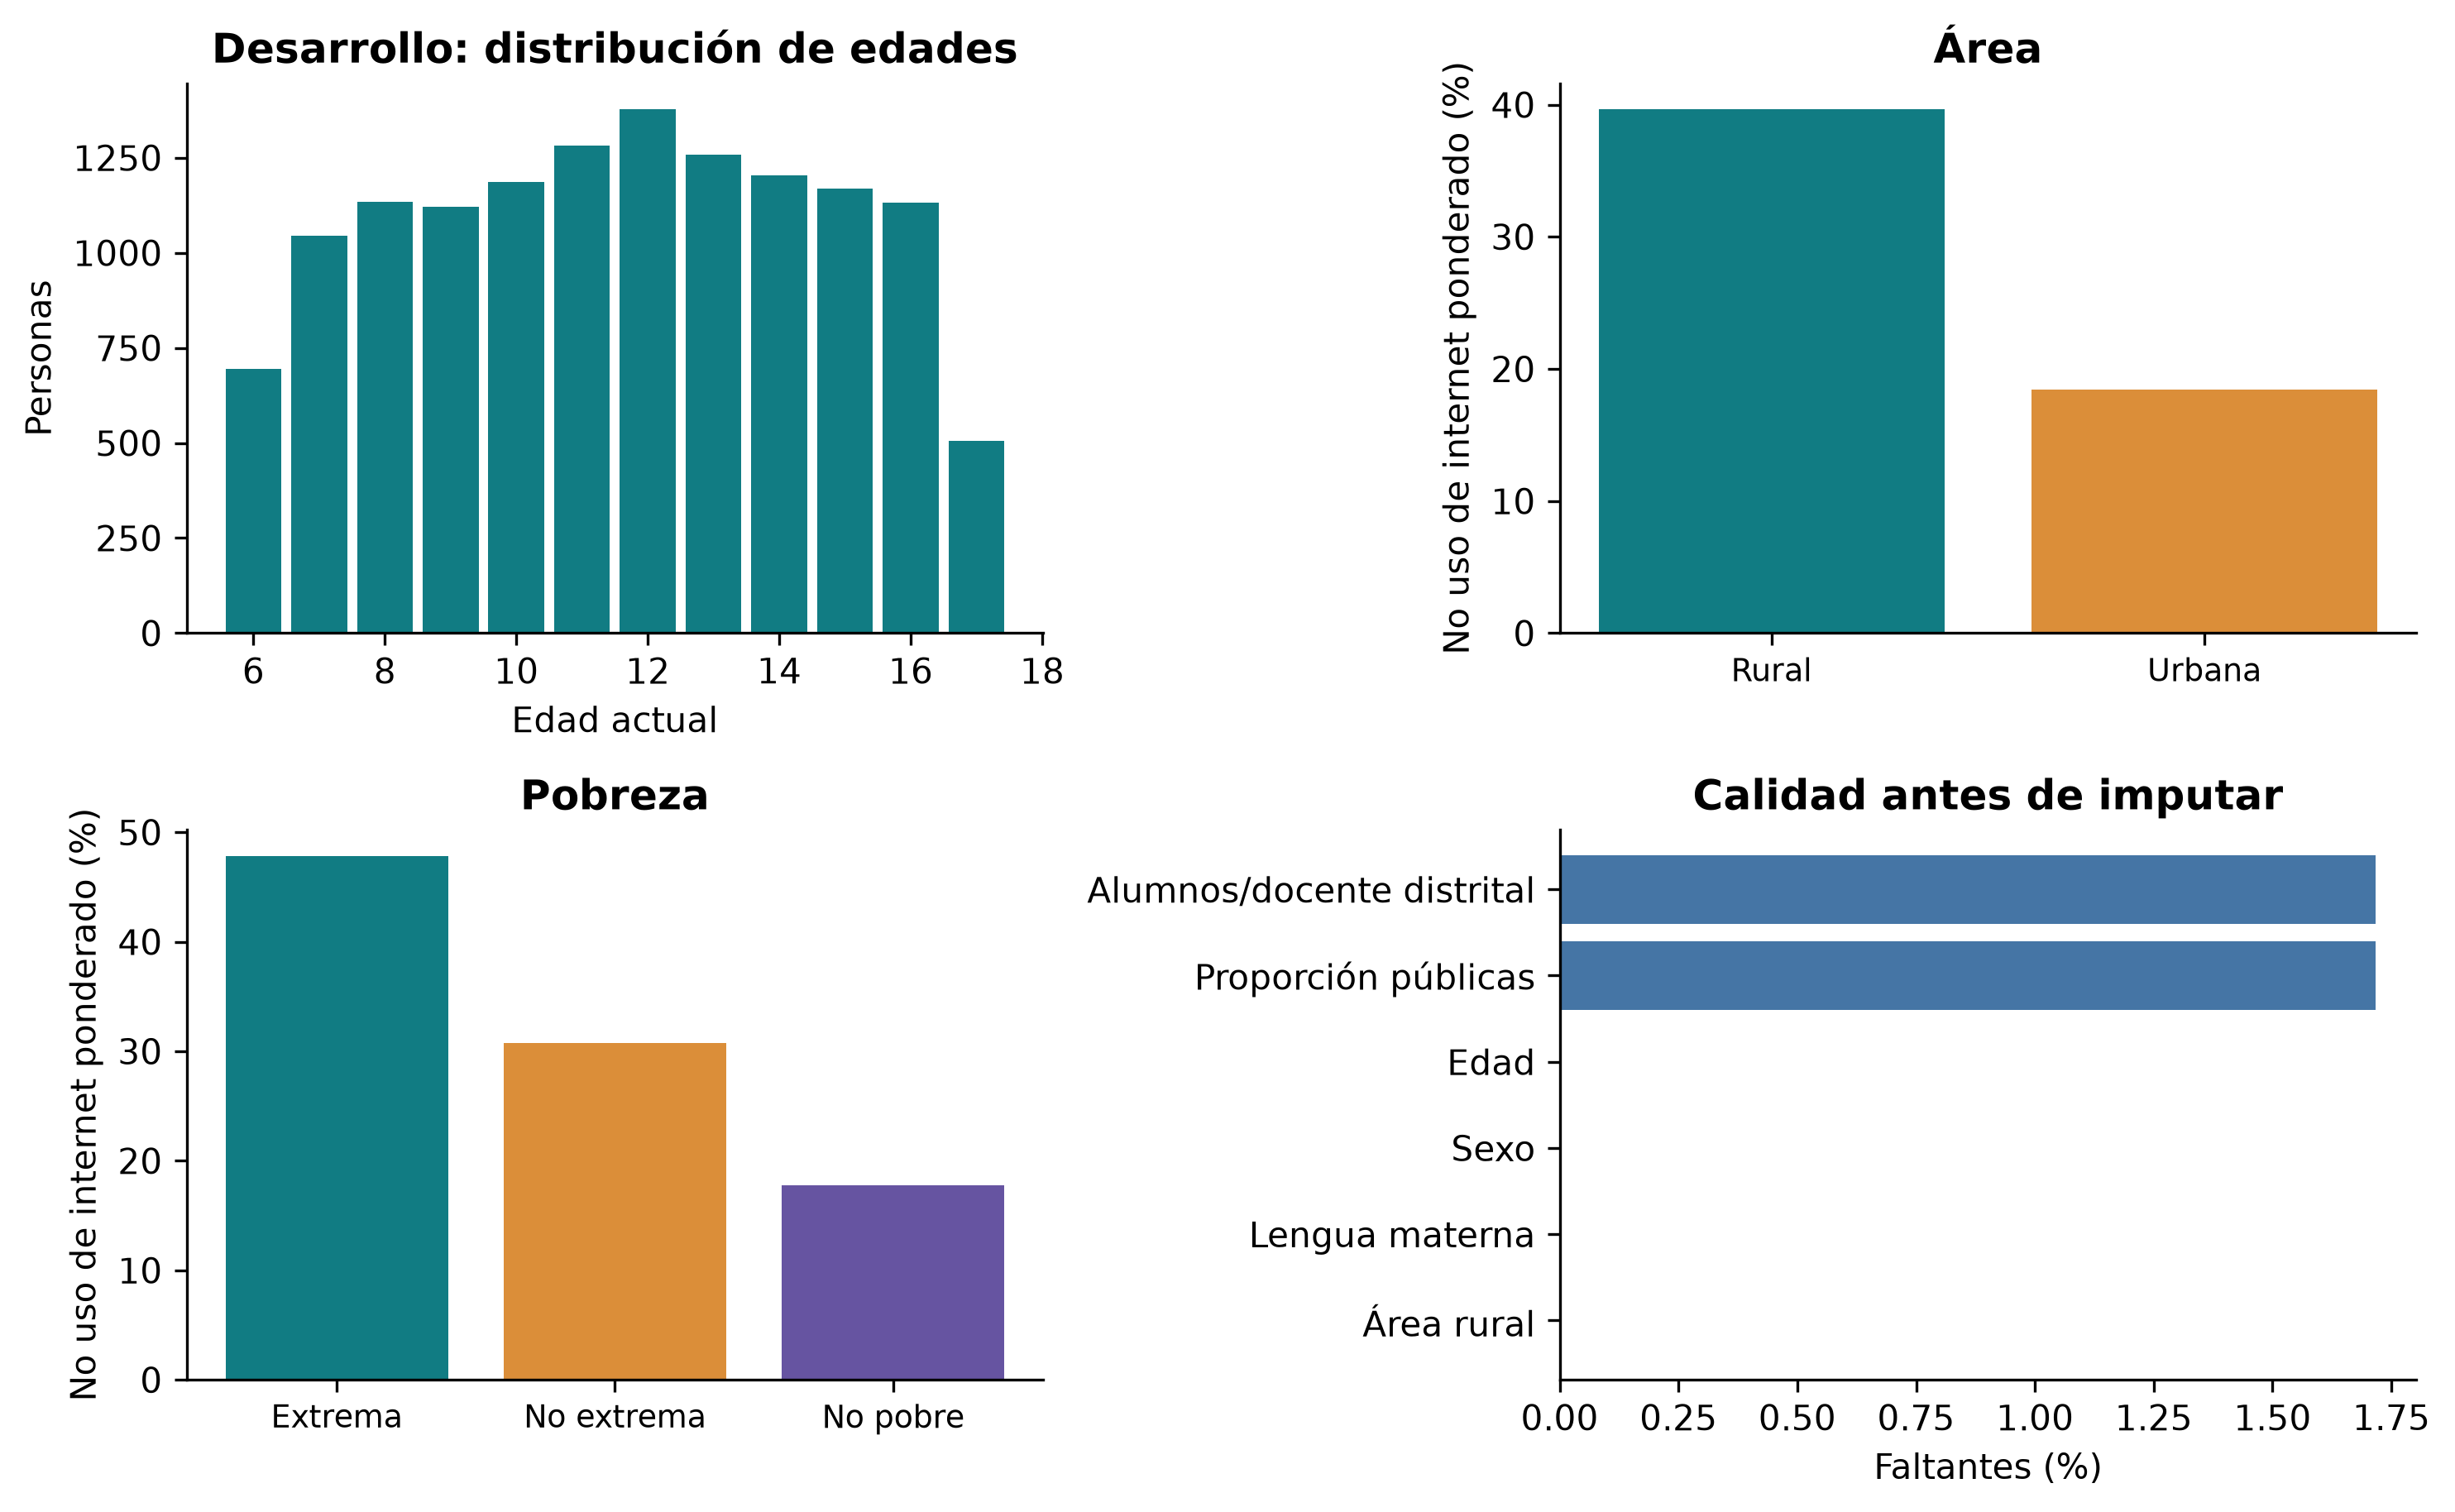

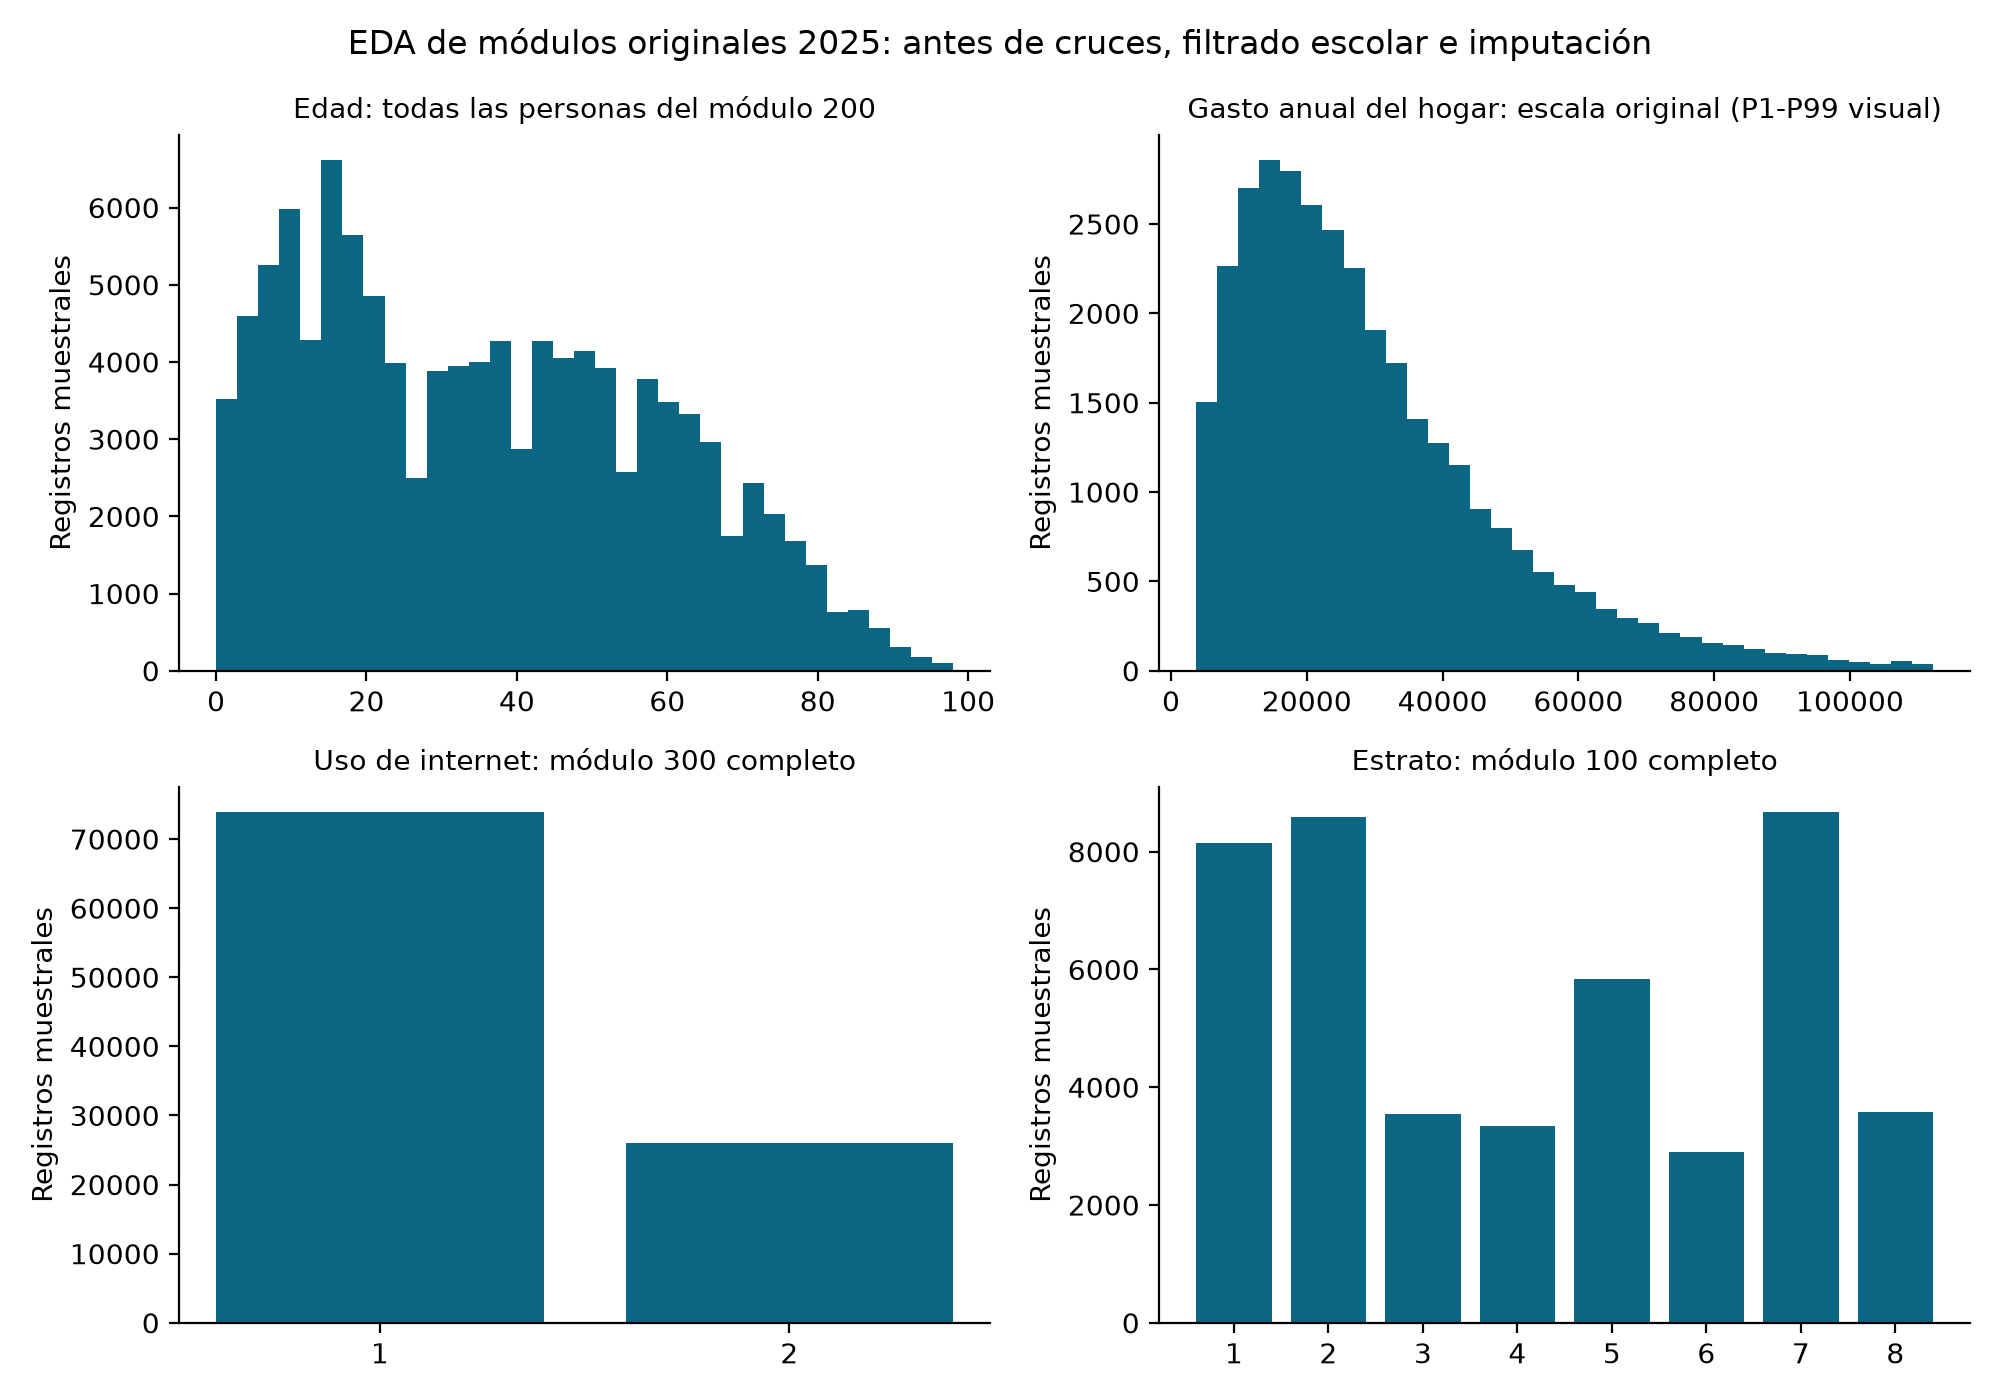

In [3]:
audit=json.loads((ROOT/'reports/tables/data_audit.json').read_text())
display(pd.DataFrame(audit['merges']).T)
print('Población:',audit['filters'])
print('Cobertura:',audit['cohort']['escale_match_rate'])
table('target_comparison.csv')
show('eda.png')
for p in sorted((ROOT/'reports/figures').glob('*raw*.png')): display(Image(filename=str(p)))

In [4]:
display(Markdown((ROOT/'docs/TARGET_DECISION.md').read_text()))
display(Markdown((ROOT/'docs/VARIABLE_VALIDATION.md').read_text()))

# Decisión científica sobre el objetivo

Revisión conceptual de la ampliación: 2026-10-28, America/Lima. La decisión de conservar la etiqueta se cerró **antes de ejecutar la nueva búsqueda de modelos**. Existe una versión predictiva anterior cuyo conjunto de prueba ya fue observado; la nueva evaluación sobre esa partición es retrospectiva, no una validación externa nueva. La guía del docente y el cuestionario tienen prioridad sobre interpretaciones previas.

## Decisión y relación con la guía

Se mantiene como objetivo principal **no uso de internet durante el mes anterior entre estudiantes de 6-17 matriculados y asistentes a primaria/secundaria**, excluida CEBA declarada. Tiene una definición directa, ventana temporal explícita y observación para todo el universo escolar definido. No se cambia la etiqueta para mejorar métricas ni para favorecer un algoritmo.

La guía propone rezago o exclusión digital efectiva, descrita con competencias y uso de internet. Esta etiqueta mide **una dimensión operacional de la exclusión tecnológica**. No identifica por sí sola ausencia de competencias digitales, exclusión persistente ni riesgo futuro. Por tanto, la equivalencia completa con el constructo multidimensional de la guía queda **parcial**. La adecuación de esta operacionalización al criterio docente es una limitación que debe reconocerse al defender el proyecto, no ocultarse con un nombre más ambicioso.

La revisión completa del cuestionario corrigió una omisión de la versión anterior: **ENAHO 2025 sí incluye un bloque de competencias TIC, P316B/P316C**, pero solo para personas de14 o más años y con saltos condicionados al uso de dispositivo. No permite observar competencias de todos los escolares de 6-17. No es correcto afirmar que estas variables no existen, ni convertir sus saltos en falta demostrada de habilidades.

## Definición matemática

El dataset integrado ya restringe a residentes habituales de 6-17. La cohorte final exige:

```text
E = 6 <= P208A <= 17
    y P306=1 y P307=1
    y P308A en {2 primaria, 3 secundaria}
    y no existe declaración P307D=1 (CEBA)
    y P314A en {1,2}
    y FACPOB07 es válido y positivo.

y = 1 si P314A=2; y=0 si P314A=1, solo en E.
```

Un faltante o código inválido en P314A no equivale a0. La exclusión de CEBA se basa en respuesta afirmativa; el NA estructural por edad de P307D no se convierte en CEBA. No se exige grado válido para etiquetar no uso, aunque la versión anterior tenía grado válido en todos los 16,544 elegibles.

La versión anterior produjo 16,544 elegibles,4,294 positivos y 12,250 negativos, en 4,040 conglomerados. Estos conteos son una referencia histórica a verificar tras reconstrucción, no un resultado de entrenamiento nuevo. La ejecución vigente escribe los conteos en `reports/tables/target_comparison.csv` y `reports/tables/target_measurement_audit.json`.

## Qué mide realmente cada rama TIC

| Rama | Medición | Universo/salto | Consecuencia |
|---|---|---|---|
| P314A | Uso individual de internet mes anterior | Personas6+ | Etiqueta principal directa. No mide destreza ni conexión del hogar. |
| P314B / P314B1 | Lugares/modalidades y dispositivos de conexión | Usuarios de internet | No son un test de competencias; sus respuestas y NA pueden revelar la etiqueta. |
| P314D | Frecuencia de uso | Usuarios | No confundir con P316; excluir del modelo de no uso. |
| P316_1...12 | Finalidades: información, comunicación, compras, banca, educación, trámites, ocio, venta, otros, software | Usuarios | P316_5=2 significa que no declaró uso educativo, no que no sabe usar herramientas. |
| P316B | Uso de computadora/laptop/tablet/similar en últimos 3 meses | Personas14+ | Si no, se salta P316C. No uso reciente de dispositivo no demuestra incapacidad. |
| P316C1...9 | Actividades informáticas concretas autorreportadas |14+ y P316B=1 | Información sobre experiencia relacionada con habilidades. Solo observable en un subconjunto seleccionado; no es prueba de desempeño. |
| P316C10 | Otras actividades | Igual subconjunto | No sumar como una habilidad uniforme comparable con cada ítem enumerado. |

El cuestionario ENAHO.01A 2025, página PDF5, confirma P314A=1 sí/2 no y el salto de no usuarios hacia P316A. Su página 6 identifica el bloque de competencias para 14+ y el salto desde P316B=2 al capítulo 400. El diccionario anual 2025, páginas PDF107-111, confirma nombres/códigos; el panel conserva las columnas `_25` y algunos rótulos heredados. Véase `docs/VARIABLE_VALIDATION.md` para el contraste por variable.

Como sensibilidad descriptiva se audita, entre 14-17 con las nueve actividades observadas, cuántos no usan internet y no reportan ninguna. Ese subconjunto no representa a todos los escolares y no crea una nueva etiqueta entrenada. No imputar C=No cuando B=No o edad < 14: los mecanismos de ausencia son parte del diseño del cuestionario.

## Comparación con rezago escolar

Se evaluó la alternativa de desfase observado edad-grado:

```text
edad_normativa = P308C+5 en primaria; P308B+11 en secundaria.
desfase = P208A-edad_normativa.
rezago_1 = I(desfase >= 1); rezago_2 = I(desfase >= 2).
```

Se requieren grados válidos 1-6 en primaria/años1-5 en secundaria, asistencia/matrícula y exclusión CEBA declarada. El [documento metodológico INEI de indicadores educativos 2022](https://www.inei.gob.pe/media/MenuRecursivo/investigaciones/indicadores-de-educacion.pdf), páginas PDF29 y33-34, fundamenta el desfase con edad actual. La [ficha ESCALE/SIAGIE](https://escale.minedu.gob.pe/tendencias-2016-portlet/servlet/tendencias/archivo?idCuadro=14&tipo=meta) emplea dos años y edad al31 de marzo; no es una definición intercambiable.

La exploración anterior encontró 6,707 casos para>=1 y 679 para>=2; la primera frecuencia varió de 10.6% en marzo a 69.4% en diciembre. Esa variación es compatible con cumpleaños y composición mensual, sin identificar por separado cada mecanismo. Los campos adicionales de nacimiento leídos del módulo 200 estaban vacíos; esto **no prueba ausencia de fechas en toda ENAHO**: el módulo 400 de Salud incluye preguntas de nacimiento. Ese módulo no es Sumaria y no se integra al objetivo principal actual. No se inventaron cumpleaños ni se restó un año automáticamente.

Rezago observado sería una alternativa legítima si se declara su definición y universos; no se adopta ahora solo para aparentar mayor ajuste a la consigna o elegir el target de mejor AUC. La claridad de P314A y su cobertura6-17 justifican mantenerlo y reconocer su alcance limitado.

## Factores de expansión y evaluación

La unidad analítica es la persona estudiante. FACPOB07, factor anual de población del módulo 200, es la referencia principal. FACTORA07, factor poblacional del módulo educativo descrito por el panel como ajustado por grupos quinquenales, se conserva para sensibilidad. FACTOR07 de Sumaria tiene unidad hogar: al repetirlo en filas de personas no se vuelve automáticamente un factor de persona. Los pesos longitudinales FACPANEL no corresponden al corte transversal seleccionado.

La ampliación compara en desarrollo estrategias sin pesos, balance de clases, pesos poblacionales y su combinación. La normalización y las masas de clase se calculan solo en el entrenamiento de cada fold. La selección se efectúa por AP ponderada FACPOB07; se presentan métricas sin ponderar y sensibilidad FACTORA07. El calibrador se aprende de predicciones OOF de desarrollo, con pesos de población y sin balance que altere artificialmente la prevalencia de referencia.

Los resultados ponderados describen esta cohorte bajo el factor empleado; no son tasas nacionales oficiales ni una reproducción de la inferencia completa del diseño complejo. La prueba por conglomerados evalúa vecindarios no vistos dentro de esta fuente y población; no garantiza distritos nuevos ni otro año.

## Fuga y predictores

Excluir P314A y todos sus derivados, P314B*, P314D, P315*, P316*, sus banderas de falta/respuesta e imputaciones. Excluir las etiquetas alternativas y las variables que definieron matrícula, asistencia y trayectoria; identificadores, coordenadas y mes no son predictores. P1144 se conserva porque mide conexión del hogar, distinta del uso individual; no autoriza inferir causalidad.

La lista principal sigue siendo explícita y se fija antes de la nueva búsqueda. Las banderas de unión ENAHO se conservan solo para auditoría. `escale_coincide` sí forma parte del conjunto de predictores como indicador contextual de disponibilidad; no contiene la etiqueta. Esa elección debe declararse de forma consistente y limita el transporte a geografías con otra cobertura. Clustering se presenta por separado y no se añade a los clasificadores como una transformación ajustada fuera de fold.

## Procedencia y límites de defensa

La fuente única de referencia se decide por la comparación ejecutada y se documenta en `docs/SOURCE_COMPARISON.md` cuando está disponible; el nombre «panel» no basta para excluir una fuente que contiene corte2025 panel y no panel. No se afirma equivalencia entre archivos por compartir recuentos; se requiere comparación por llaves y variables.

ESCALE es contexto por distrito/área de residencia. ENAHO no identifica aquí el local escolar asistido: no asignar a cada estudiante las instalaciones de un colegio concreto. Las asociaciones predictivas y SHAP no demuestran causalidad. Quienes no están matriculados o no asisten quedan fuera de la cohorte final; no se generaliza a toda la niñez ni a todas las dimensiones de exclusión educativa.

La rúbrica de competencias debe permanecer como adaptación explícita mientras la medición no identifique todo el constructo. Resolver esa limitación exigiría un instrumento comparable para 6-17 o una redefinición y validación de población/constructo; no es un faltante que se arregle llenando NA con ceros.


# Validación conceptual de variables y factores de expansión

Revisión: 2026-10-28, America/Lima. Las variables se contrastaron con el cuestionario ENAHO 2025 del material docente y el diccionario anual oficial 2025. Las páginas indicadas son páginas PDF, contadas desde 1. El diccionario panel contiene nombres heredados y algunos rótulos que no reproducen el cuestionario de 2025; se prioriza el significado de la pregunta del cuestionario y se verifica el contenido observado.

## Fuentes comprobadas

- **Q01**: `INEI/1041-Modulo1479.zip!1041-Modulo1479/CUESTIONARIO_ENAHO01_2025.pdf`, páginas 7-8: miembros, ausencia, presencia y edad.
- **Q01A**: `INEI/1041-Modulo1475.zip!1041-Modulo1475/CUESTIONARIO_ENAHO01A_2025.pdf`, páginas 2, 5 y 6: educación, uso de internet y competencias TIC.
- **D25**: [INEI, Diccionario de Datos ENAHO 2025, mayo de 2026](https://proyectos.inei.gob.pe/iinei/srienaho/Descarga/DocumentosMetodologicos/2025-55/20_Diccionario_2025.pdf): páginas 14, 16, 30-31, 94-95, 107-111, 119 y 375.
- **DP**: `Diccionario_panel_2021_2025.pdf` dentro de los módulos originales: páginas 588-590, 594-595, 599, 660-667; describe campos con sufijo `_25`.

El sufijo anual se quita únicamente después de seleccionar 2025. No se mezclan las respuestas de años anteriores para completar respuestas de 2025.

## Variables exigidas por la guía

| Variable | Significado y códigos verificados | Papel y control |
|---|---|---|
| P1121 | Selección de electricidad como alumbrado: 1 seleccionado, 0 pase/no selección (D25 p. 14). Es una alternativa de respuesta múltiple, no una pregunta binaria con 2=no. | Se deriva electricidad=1/0 solo para códigos válidos; NA permanece NA. No mide horas de servicio, estabilidad ni calidad eléctrica. |
| P1144 | Conexión a internet fijo o móvil del hogar: 1 seleccionado, 0 pase/no selección (D25 p. 16). | internet_hogar=1/0; diferente del uso individual P314A. No se interpreta como internet fijo exclusivamente. |
| P207 | Sexo registrado: 1 hombre, 2 mujer (D25 p. 30). | Variable categórica; los códigos no son una magnitud. |
| P208A | Edad cumplida al entrevistar, no edad al inicio del año escolar (D25 p. 30). 99 es un código de falta de información. | Universo principal 6-17. Edad se admite para predecir no uso de internet; no se usaría de igual forma para un target que la incluye en su definición. |
| P203 | Relación con el jefe del hogar: categorías de parentesco (DP p. 660 y D25 p. 30). | Auditoría, no predictor principal. No confundir miembro del hogar con residente habitual. |
| P300A | Lengua materna; 1 quechua, 2 aimara, 4 castellano; existen otras lenguas y categorías (Q01A p. 2). | Se conserva la categoría original y se codifica one-hot. Un gráfico de códigos no significa una escala continua de lengua. |
| P306 | Matrícula en el año actual: 1 sí, 2 no (Q01A p. 2). | Define población elegible, no predictor. |
| P307 | Asistencia actual: 1 sí, 2 no (Q01A p. 2). | Define población. El rótulo panel que aún menciona educación a distancia no sustituye la pregunta del cuestionario 2025. |
| P307D | Educación primaria/secundaria recibida en CEBA: 1 sí, 2 no. Pregunta para personas de 14 o más años con la trayectoria educativa indicada (Q01A p. 2). | Se excluye CEBA declarado; un salto por edad no equivale a una respuesta afirmativa ni a ausencia aleatoria. |
| P308A | Nivel en el que está matriculado: 2 primaria, 3 secundaria (Q01A p. 2). | Define EBR de interés, con exclusión CEBA declarada. |
| P308B / P308C | Año de secundaria / grado de primaria; el cuestionario separa año y grado (Q01A p. 2; DP p. 590). | Secundaria acepta año 1-5 y primaria grado1-6. No usar P308B como grado de primaria. Los campos P308B1... son opiniones y no el año escolar. |
| P314A | Uso del servicio de internet durante el mes anterior: 1 sí, 2 no (Q01A p. 5; D25 p. 107). | y=1 si 2; y=0 si 1. NA u otro código no es una etiqueta negativa. No prueba destreza ni incapacidad digital. |
| P314B_1...7 | Lugares/modalidades de conexión: hogar, trabajo, establecimiento educativo, cabina, otra casa, otro, acceso móvil (Q01A p. 5). | Preguntas de respuesta múltiple condicionadas al uso; códigos seleccionados difieren por columna. Se excluyen del modelo de P314A, incluso sus faltantes. |
| P314B1_* | Dispositivos de uso: computadora, laptop, tablet, celular con/sin plan, otros (Q01A p. 5). | No medir competencias con disponibilidad/uso de dispositivo. Revisar códigos reales: el diccionario panel contiene rótulos inconsistentes en B1_8/B1_9. |
| P314D | Frecuencia del uso: 1 diario, 2 semanal, 3 mensual, 4 cada 2 meses o más (Q01A p. 5). | No es P316. Excluido por dependencia de la etiqueta; puede describirse condicionando al universo de usuarios. |
| P316_1...12 | Finalidades del uso de internet; P316_5 educación/capacitación, P316_12 descargar software (Q01A p. 5; D25 pp109-110). | Son actividades/finalidades, no examen de competencias. P316_5=2 no significa falta de habilidades. NA de no usuarios es estructural. |
| P316B | Uso de computadora, laptop, tablet o similar durante los últimos 3 meses, para personas de 14+ (Q01A p. 6). | No es la misma ventana ni universo de P314A. Si2, se salta el inventario P316C. |
| P316C1...9 / C10 | Actividades informáticas autorreportadas: archivos, copiar/pegar, adjuntos, fórmulas, dispositivos, software, presentaciones, transferencia, programación; C10=otras (Q01A p. 6; D25 pp110-111). | Información directa sobre actividades relacionadas con habilidades, solo en 14+ y con dispositivo usado. No observado no equivale a incapacidad. No sumar C10 como una destreza comparable a cada actividad enumerada. Excluidas del modelo principal. |
| POBREZA | 1 pobre extremo, 2 pobre no extremo, 3 no pobre (D25 p. 375). | Categórica; no reetiquetar3 como mayor pobreza. Es predictor del no uso, no el objetivo. |
| INGHOG2D | Ingreso neto total del hogar, anualizado (Sumaria). | Ingreso mensual per cápita=INGHOG2D/(12*MIEPERHO), con denominador válido positivo. No son ingresos personales del alumno. |
| GASHOG2D | Gasto total bruto del hogar, anualizado (Sumaria; D25 p. 375). | Gasto mensual per cápita=GASHOG2D/(12*MIEPERHO). No llamarlo gasto monetario, que corresponde a otro campo. |
| FACTOR07 | Factor anual registrado en archivos de hogar/Sumaria (D25 p. 375). | Se conserva como peso de hogar. Repetirlo tras unir a personas no cambia su unidad y no autoriza estimar hogares sumándolo por alumno. |
| FACPOB07 | Factor anual de población (D25 p. 31; DP p. 588). | peso_persona: ponderación principal por corresponder a la unidad estudiante/persona. Nunca predictor. |
| FACTORA07 | Factor anual de población en el módulo educativo (D25 p. 119); DP p. 599 lo describe ajustado por grupos quinquenales. | peso_educacion: sensibilidad documentada. No confundir con el factor de empleo de otros módulos que comparte nombre. |

## Competencias: evidencia y saltos

La revisión anterior del proyecto no había auditado toda la página 6 del cuestionario. **Sí existe un bloque de competencias TIC**, pero no observa de manera completa el universo escolar de 6-17. Los6-13 están fuera de su universo; además P316B=2 evita preguntar C. La ausencia por esos mecanismos no es una respuesta negativa a cada habilidad.

La comprobación directa del CSV crudo de educación, con identificadores de 2025 y sin filtrar edad, encontró 106,958 registros: P314A válido en 99,919; P316B en 84,784 (20,746 sí, 64,038 no); cada P316C1...10 en 20,746. Estos conteos describen el módulo educativo completo del archivo panel docente, no la cohorte final ni la población nacional. Su cobertura específica por edad/cohorte debe consultarse en las tablas de auditoría generadas en la reconstrucción.

Un indicador de baja actividad entre los14-17 que respondieron C sería posible, pero requiere fijar umbral y universo, interpretar selección por uso de dispositivo, y validación externa. No demuestra falta de competencias de los de 6-13, ni de quienes no usaron dispositivo recientemente. Inventar ceros en los saltos produciría una aparente medición completa que el cuestionario no respalda.

## Ponderación y sensibilidad

El protocolo conserva FACPOB07 como peso principal de evaluación y perfilamiento. Compara en desarrollo cuatro estrategias de entrenamiento: sin pesos, solo balance de clase, solo población y población más balance de clase; cada normalización y frecuencia de clase se obtiene en el entrenamiento del fold. El desbalance se considera aunque una estrategia sin balance explícito pueda ganar por AP.

La comparación por FACPOB07/FACTORA07 evalúa sensibilidad al factor. Las métricas sin peso describen la muestra; las ponderadas describen el estimando auxiliar de esta cohorte según el factor. Ni el ajuste ponderado ni un bootstrap de conglomerados reproducen automáticamente toda la estratificación del diseño ENAHO. No se reportan tasas nacionales oficiales ni intervalos de encuesta completos.

## Límite temporal de la validación

El conjunto de prueba de este proyecto ya había sido observado en la versión anterior. La ampliación de búsqueda selecciona configuraciones solo en desarrollo y conserva la partición original; se declara evaluación retrospectiva de un holdout previamente observado. No se afirma que sea una validación externa nueva, ni que la semilla borre ese historial.


## Conclusión
Revise los descartes, los códigos y la cobertura antes de interpretar los datos. P314A mide uso en el mes anterior; no es una prueba de competencias. La imputación y el escalado del modelado se ajustan después, dentro de cada fold. Las tasas de esta cohorte no son cifras oficiales nacionales.